# Recherche et compréhension du phishing

## Définition du Phishing

Le phishing ou hameçonnage en français est une technique de la cybercriminalité qui consiste à tromper une personne pour lui soutirer des informations.

Le terme phishing est un jeu de mots dérivé de l'anglais **fishing** (pêche), en référence à l'idée de « pêcher » des informations sensibles auprès d'utilisateurs crédules. La lettre **« ph »** est un héritage de la culture *phreaking* des années 1970, liée au piratage téléphonique.

### Contexte et ampleur du phénomène

Le phishing constitue aujourd'hui l'une des menaces les plus répandues et les plus coûteuses dans le paysage de la cybersécurité. Plusieurs rapports récents illustrent l'ampleur du problème :

- Selon l'**Anti-Phishing Working Group (APWG)** (2025), plus de **7,8 millions** de sites de phishing ont été détectés en 2025, un chiffre en augmentation constante d'année en année.
- Le rapport **Verizon Data Breach Investigations Report (DBIR) 2024** indique que le phishing est impliqué dans environ **36 % des violations de données**.
- L'**ANSSI** signale régulièrement dans ses rapports annuels que le phishing est la porte d'entrée principale des attaques par rançongiciel (*ransomware*).
- Le coût moyen d'une violation de données est estimé à **plusieurs millions de dollars** par incident selon le rapport **IBM Cost of a Data Breach 2024**.

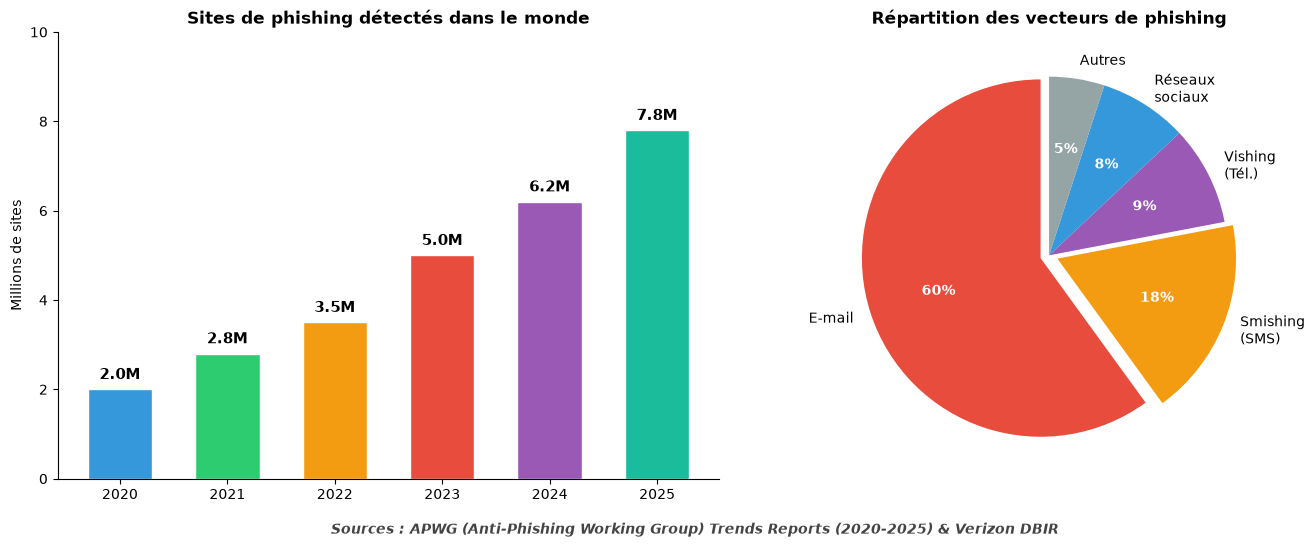

In [18]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# --- Graphique 1 : Évolution du nombre d'attaques ---
years = ['2020', '2021', '2022', '2023', '2024', '2025']
attacks = [2.0, 2.8, 3.5, 5.0, 6.2, 7.8]
colors = ['#3498db', '#2ecc71', '#f39c12', '#e74c3c', '#9b59b6', '#1abc9c']

bars = axes[0].bar(years, attacks, color=colors, width=0.6, edgecolor='white')
for bar, val in zip(bars, attacks):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.15,
                 f'{val}M', ha='center', va='bottom', fontweight='bold', fontsize=11)
axes[0].set_title("Sites de phishing détectés dans le monde", fontweight='bold', fontsize=12)
axes[0].set_ylabel("Millions de sites")
axes[0].set_ylim(0, 10)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

# --- Graphique 2 : Répartition des vecteurs ---
labels = ['E-mail', 'Smishing\n(SMS)', 'Vishing\n(Tél.)', 'Réseaux\nsociaux', 'Autres']
sizes = [60, 18, 9, 8, 5]
colors_pie = ['#e74c3c', '#f39c12', '#9b59b6', '#3498db', '#95a5a6']
explode = (0.05, 0.05, 0, 0, 0)

wedges, texts, autotexts = axes[1].pie(
    sizes, labels=labels, autopct='%1.0f%%', colors=colors_pie,
    explode=explode, startangle=90, textprops={'fontsize': 10}
)
for t in autotexts:
    t.set_fontweight('bold')
    t.set_color('white')
axes[1].set_title("Répartition des vecteurs de phishing", fontweight='bold', fontsize=12)

# --- MENTION DE LA SOURCE INTÉGRÉE DANS LE CODE ---
fig.text(0.5, 0.02, 
         "Sources : APWG (Anti-Phishing Working Group) Trends Reports (2020-2025) & Verizon DBIR", 
         ha="center", fontsize=10, style='italic', color='#444444', fontweight='bold')

plt.tight_layout()
plt.subplots_adjust(bottom=0.12)  # Espace réservé pour ne pas couper la source
plt.savefig("statistiques_phishing.png", dpi=200, bbox_inches='tight')
plt.show()

*Figure 1 : Évolution du nombre de sites de phishing détectés dans le monde (gauche) et répartition des vecteurs d'attaque (droite). Sources : APWG Trends Reports (2020-2025) et Verizon DBIR (2024).*

### Pourquoi le phishing est-il si efficace ?

Plusieurs facteurs expliquent la persistance et l'efficacité du phishing :

- **L'exploitation des biais cognitifs** : les attaquants jouent sur l'urgence (« Votre compte sera suspendu dans 24 heures »), la peur (« Activité suspecte détectée »), la curiosité ou l'autorité (« Message de votre direction »). Ces leviers psychologiques court-circuitent la réflexion rationnelle de l'utilisateur.
- **La sophistication croissante** : les campagnes modernes utilisent des designs soignés, des logos officiels, des adresses e-mail crédibles et des sites web quasi identiques aux originaux, rendant la détection visuelle de plus en plus difficile.
- **Le volume** : les attaquants envoient des millions de messages automatisés. Même avec un taux de réussite inférieur à 1 %, le retour sur investissement reste considérable.
- **L'accessibilité des outils** : des kits de phishing (*phishing-as-a-service*) sont désormais disponibles sur le dark web, permettant à des individus peu compétents techniquement de lancer des campagnes crédibles.

### Enjeux de la détection automatique

Face à ce volume massif et à cette sophistication croissante, la détection manuelle par l'utilisateur n'est plus suffisante. Les filtres **anti-spam** et les listes noires de domaines, bien qu'utiles, réagissent souvent *a posteriori* : un site de phishing peut être créé, exploité et détruit en quelques heures, bien avant d'être signalé et bloqué.

C'est dans ce contexte que l'intelligence artificielle et le machine learning offrent une piste prometteuse : plutôt que de reposer sur des listes statiques, un modèle de classification peut apprendre à reconnaître les caractéristiques structurelles des **URL malveillantes** et ainsi détecter des menaces inédites en temps réel. C'est précisément l'objectif du projet **URLShield AI**.

## Fonctionnement

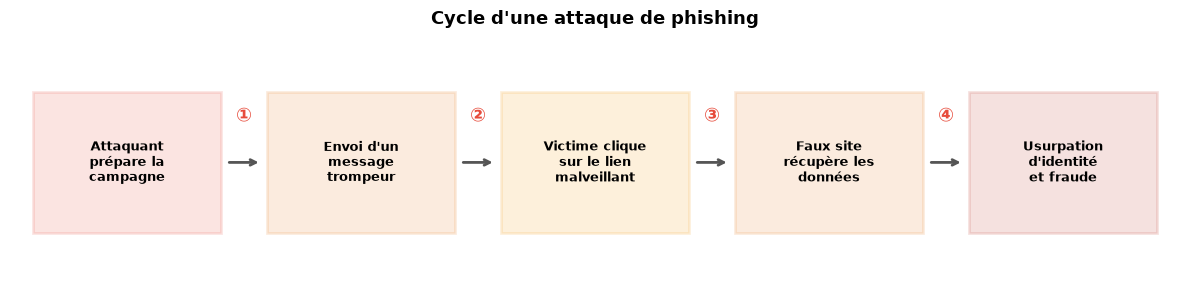

In [19]:
fig, ax = plt.subplots(figsize=(12, 3))

steps = [
    "Attaquant\nprépare la\ncampagne",
    "Envoi d'un\nmessage\ntrompeur",
    "Victime clique\nsur le lien\nmalveillant",
    "Faux site\nrécupère les\ndonnées",
    "Usurpation\nd'identité\net fraude"
]
colors_steps = ['#e74c3c', '#e67e22', '#f39c12', '#e67e22', '#c0392b']
positions = [1, 3, 5, 7, 9]

for i, (pos, step, color) in enumerate(zip(positions, steps, colors_steps)):
    rect = plt.Rectangle((pos - 0.8, 0.4), 1.6, 1.2,
                          facecolor=color, alpha=0.15,
                          edgecolor=color, linewidth=2, zorder=2)
    ax.add_patch(rect)
    ax.text(pos, 1.0, step, ha='center', va='center',
            fontsize=9, fontweight='bold', zorder=3)
    if i < len(steps) - 1:
        ax.annotate('', xy=(positions[i+1] - 0.85, 1.0),
                    xytext=(pos + 0.85, 1.0),
                    arrowprops=dict(arrowstyle='->', color='#555', lw=2))
        ax.text((pos + positions[i+1]) / 2, 1.35, f'①②③④'[i],
                ha='center', fontsize=14, color='#e74c3c', fontweight='bold')

ax.set_xlim(0, 10)
ax.set_ylim(0, 2)
ax.axis('off')
ax.set_title("Cycle d'une attaque de phishing", fontweight='bold', fontsize=13, pad=15)
plt.tight_layout()
plt.savefig("cycle_phishing.png", dpi=200, bbox_inches='tight')
plt.show()

### Phishing par e-mail (*email phishing*)

C'est la forme la plus classique et la plus répandue. L'attaquant envoie un **e-mail frauduleux** imitant un expéditeur légitime (banque, réseau social, service de livraison). Le message contient généralement :

- **Un lien** redirigeant vers un site web contrefait, hébergé sur un domaine contrôlé par l'attaquant.
- **Une pièce jointe** malveillante (document Word avec macro, fichier PDF piégé, archive ZIP contenant un exécutable).
- **Un formulaire** intégré directement dans le corps du mail demandant des informations sensibles.

**Exemple typique** : un e-mail prétendument envoyé par PayPal informe l'utilisateur d'une « transaction suspecte » et l'invite à cliquer sur un lien pour « vérifier son identité ». Le lien mène vers une réplique de la page de connexion PayPal hébergée sur un domaine tel que `paypal-secure-login.xyz`.

### Spear phishing

Le spear phishing est une variante ciblée du phishing. Contrairement aux campagnes de masse, l'attaquant se renseigne préalablement sur sa victime (nom, fonction, entreprise, relations professionnelles) pour personnaliser le message et augmenter ses chances de succès.

Cette technique est particulièrement utilisée dans les attaques contre les entreprises (*Business Email Compromise* ou BEC), où l'attaquant peut se faire passer pour un dirigeant et demander un virement urgent au service comptable.

### Smishing (phishing par SMS)

Le smishing (*SMS phishing*) utilise les messages texte pour atteindre la victime. L'utilisateur reçoit un SMS contenant un lien court (souvent via un raccourcisseur d'URL comme `bit.ly`) menant vers un site frauduleux.

**Exemple** : « [Colissimo] Votre colis n'a pas pu être livré. Suivez votre envoi ici : bit.ly/3xK9mQ2 ». La victime est redirigée vers un faux site de livraison qui lui demande ses coordonnées bancaires pour « payer des frais de douane ».

Le smishing est particulièrement efficace car les utilisateurs font souvent davantage confiance aux SMS qu'aux e-mails et les filtres anti-spam sont moins performants sur ce canal.

### Vishing (phishing vocal)

Le vishing (*voice phishing*) repose sur un **appel téléphonique**. L'attaquant se fait passer pour un conseiller bancaire, un agent du support technique ou un représentant d'une administration. Il utilise la pression verbale et l'urgence pour convaincre la victime de communiquer des informations sensibles ou de se rendre sur un site malveillant.

L'émergence de l'intelligence artificielle générative et des techniques de clonage vocal rend cette menace de plus en plus crédible.

### Clone phishing

Dans le clone phishing, l'attaquant intercepte ou reproduit un e-mail légitime que la victime a déjà reçu, puis en crée une copie quasi identique en remplaçant les liens ou les pièces jointes par des versions malveillantes. La familiarité du message original rend la détection très difficile.

### Pharming

Le pharming est une technique plus avancée qui ne repose pas sur un message trompeur, mais sur la manipulation de la résolution DNS. L'attaquant redirige le trafic d'un site légitime vers un serveur frauduleux, soit en compromettant un serveur DNS, soit en modifiant le fichier `hosts` de la machine de la victime. Ainsi, même si l'utilisateur tape correctement l'URL dans son navigateur, il est dirigé vers le faux site.

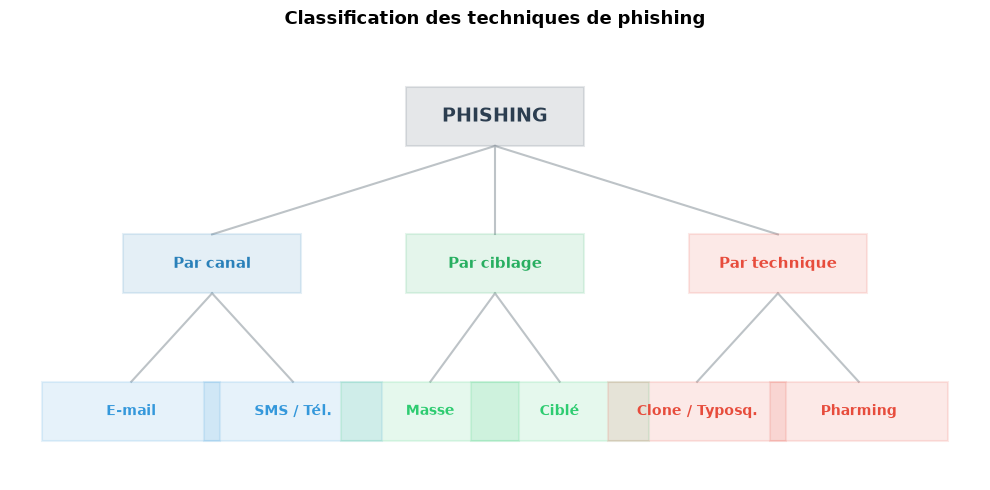

In [20]:
fig, ax = plt.subplots(figsize=(10, 5))

nodes = {
    "PHISHING": (5, 4, '#2c3e50', 14),
    "Par canal": (1.5, 2.5, '#2980b9', 11),
    "Par ciblage": (5, 2.5, '#27ae60', 11),
    "Par technique": (8.5, 2.5, '#e74c3c', 11),
    "E-mail": (0.5, 1, '#3498db', 10),
    "SMS / Tél.": (2.5, 1, '#3498db', 10),
    "Masse": (4.2, 1, '#2ecc71', 10),
    "Ciblé": (5.8, 1, '#2ecc71', 10),
    "Clone / Typosq.": (7.5, 1, '#e74c3c', 10),
    "Pharming": (9.5, 1, '#e74c3c', 10),
}

edges = [
    ("PHISHING", "Par canal"), ("PHISHING", "Par ciblage"), ("PHISHING", "Par technique"),
    ("Par canal", "E-mail"), ("Par canal", "SMS / Tél."),
    ("Par ciblage", "Masse"), ("Par ciblage", "Ciblé"),
    ("Par technique", "Clone / Typosq."), ("Par technique", "Pharming"),
]

for src, dst in edges:
    x1, y1 = nodes[src][0], nodes[src][1]
    x2, y2 = nodes[dst][0], nodes[dst][1]
    ax.plot([x1, x2], [y1 - 0.3, y2 + 0.3], color='#bdc3c7', linewidth=1.5, zorder=1)

for name, (x, y, color, size) in nodes.items():
    rect = plt.Rectangle((x - 1.1, y - 0.3), 2.2, 0.6,
                          facecolor=color, alpha=0.12,
                          edgecolor=color, linewidth=1.5, zorder=2)
    ax.add_patch(rect)
    ax.text(x, y, name, ha='center', va='center',
            fontsize=size, fontweight='bold', color=color, zorder=3)

ax.set_xlim(-1, 11)
ax.set_ylim(0.3, 4.8)
ax.axis('off')
ax.set_title("Classification des techniques de phishing", fontweight='bold', fontsize=13, pad=10)
plt.tight_layout()
plt.savefig("classification_phishing.png", dpi=200, bbox_inches='tight')
plt.show()

## Les caractéristiques des URL malveillantes

Cette section détaille les propriétés structurelles et lexicales qui distinguent les URL de phishing des URL légitimes. Ces caractéristiques constituent les variables (*features*) sur lesquelles s'appuiera le modèle de machine learning du projet URLShield AI.

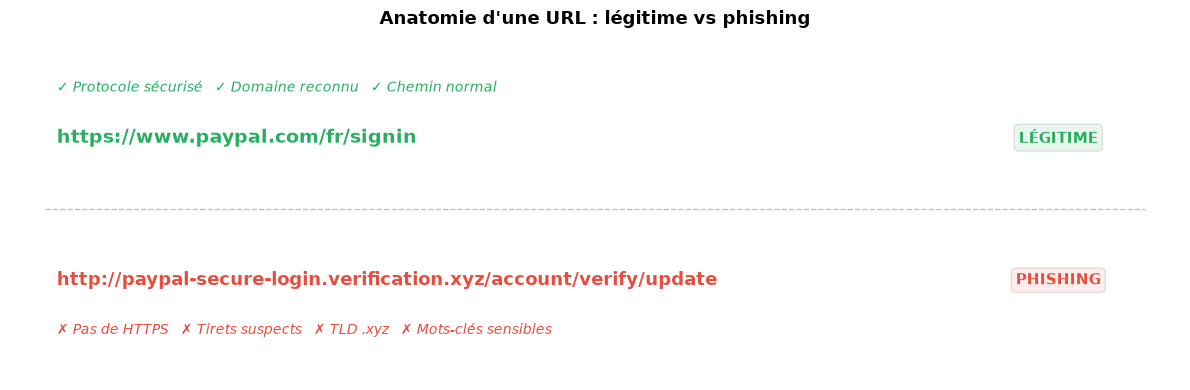

In [21]:
fig, ax = plt.subplots(figsize=(12, 4))

# URL légitime
ax.text(0.5, 2.0, "https://www.paypal.com/fr/signin",
        fontsize=14, fontweight='bold', color='#27ae60', va='center')
ax.text(0.5, 2.35, "✓ Protocole sécurisé   ✓ Domaine reconnu   ✓ Chemin normal",
        fontsize=10, color='#27ae60', style='italic', va='center')

# URL de phishing
ax.text(0.5, 1.0, "http://paypal-secure-login.verification.xyz/account/verify/update",
        fontsize=13, fontweight='bold', color='#e74c3c', va='center')
ax.text(0.5, 0.65, "✗ Pas de HTTPS   ✗ Tirets suspects   ✗ TLD .xyz   ✗ Mots-clés sensibles",
        fontsize=10, color='#e74c3c', style='italic', va='center')

# Séparateur
ax.axhline(y=1.5, xmin=0.03, xmax=0.97, color='#bdc3c7', linestyle='--', linewidth=1)

# Labels
ax.text(11.2, 2.0, "LÉGITIME", fontsize=11, fontweight='bold',
        color='#27ae60', ha='center', va='center',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='#27ae60', alpha=0.1))
ax.text(11.2, 1.0, "PHISHING", fontsize=11, fontweight='bold',
        color='#e74c3c', ha='center', va='center',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='#e74c3c', alpha=0.1))

ax.set_xlim(0, 12.5)
ax.set_ylim(0.3, 2.7)
ax.axis('off')
ax.set_title("Anatomie d'une URL : légitime vs phishing", fontweight='bold', fontsize=13, pad=10)
plt.tight_layout()
plt.savefig("anatomie_url.png", dpi=200, bbox_inches='tight')
plt.show()

### Longueur de l'URL

Les URL de phishing ont tendance à être significativement plus longues que les URL légitimes. Les attaquants ajoutent de multiples sous-répertoires, des paramètres de requête superflus et des chaînes encodées pour :

- Imiter la structure d'un site légitime (`/login/secure/verify/account/update/`).
- Dissimuler le véritable domaine dans une URL que l'utilisateur ne lira pas en entier.
- Contourner les filtres basés sur des motifs simples.

**Variable associée** : `url_length` — nombre total de caractères dans l'URL.

### Profondeur du chemin (*path depth*)

La profondeur d'une URL correspond au nombre de sous-répertoires dans le chemin. Par exemple, `https://example.com/a/b/c/page` a une profondeur de 4. Les URL de phishing présentent souvent une profondeur anormalement élevée, car les attaquants reproduisent l'arborescence du site imité.

**Variable associée** : `path_depth` — nombre de segments séparés par `/` dans le chemin.

### Présence d'une adresse IP

Une URL légitime utilise presque toujours un nom de domaine lisible (`www.banque.fr`). En revanche, les URL de phishing contiennent parfois une adresse IP brute à la place du nom de domaine, par exemple `http://192.168.1.45/login`. Cette pratique est rare dans les sites légitimes et constitue un signal fort de malveillance.

**Variable associée** : `has_ip_address` — variable binaire (0 ou 1).

### Caractères spéciaux et obfuscation

Les attaquants utilisent divers caractères spéciaux pour tromper l'utilisateur ou masquer la véritable destination de l'URL :

- **L'arobase (`@`)** : dans une URL comme `http://www.banque.fr@evil.com/login`, le navigateur se connecte en réalité à `evil.com`. Tout ce qui précède le `@` est ignoré.
- **Le tiret (`-`)** : utilisé en excès pour imiter un nom de domaine légitime (`www-paypal-secure-login.com`).
- **L'encodage hexadécimal (`%xx`)** : les caractères peuvent être encodés pour rendre l'URL illisible (`%2F` pour `/`, `%40` pour `@`).
- **Les redirections multiples** : l'URL contient des paramètres comme `redirect=`, `url=`, `next=` qui pointent vers d'autres adresses.

**Variables associées** : `count_at_symbol`, `count_dash`, `percent_encoded_chars`, `count_redirect_keywords`.

### Sous-domaines multiples

Une URL légitime possède généralement un ou deux sous-domaines (`www.example.com`, `mail.example.com`). Les URL de phishing peuvent en comporter un nombre anormalement élevé pour créer une illusion de légitimité :

`http://login.secure.account.verification.evil-domain.xyz/bank/`

Ici, l'utilisateur peut lire « login », « secure », « account » et « verification » et croire qu'il s'agit d'un site officiel, alors que le véritable domaine est `evil-domain.xyz`.

**Variable associée** : `num_subdomains` — nombre de sous-domaines dans l'URL.

### Typosquatting et homoglyphes

Le typosquatting consiste à enregistrer un nom de domaine très proche d'un domaine légitime, en exploitant les fautes de frappe courantes :

- Substitution de caractères : `g00gle.com` (zéros au lieu de « o »), `amaz0n.com`.
- Ajout ou omission de lettres : `faceb0ok.com`, `twiter.com`.
- Inversion de lettres : `gogle.com`.

Les homoglyphes vont plus loin en utilisant des caractères Unicode visuellement identiques à des caractères latins. Par exemple, le « а » cyrillique (U+0430) est visuellement indiscernable du « a » latin (U+0061), ce qui permet de créer un domaine comme `pаypal.com` (avec un « a » cyrillique) qui semble identique à `paypal.com`.

**Variables associées** : `typosquatting_score`, `suspicious_tld`, `domain_similarity_to_known_brand`.

### Extensions de domaine suspectes (TLD)

Certains domaines de premier niveau (*Top-Level Domains* ou TLD) sont statistiquement plus associés au phishing en raison de leur faible coût d'enregistrement et de leur réglementation laxiste : `.xyz`, `.top`, `.click`, `.buzz`, `.tk`, `.ml`, `.ga`. À l'inverse, des TLD comme `.gov`, `.edu` ou `.fr` sont plus contrôlés et donc moins fréquemment utilisés par les attaquants.

**Variable associée** : `suspicious_tld` — variable binaire ou catégorielle basée sur une liste de TLD à risque.

### Présence de mots-clés sensibles

Les URL de phishing contiennent souvent des mots-clés liés à l'authentification ou à la sécurité, destinés à rassurer la victime ou à imiter les pages de connexion :

`login`, `signin`, `verify`, `secure`, `account`, `update`, `password`, `confirm`, `banking`, `credential`.

La présence de ces termes dans le chemin ou le nom de domaine est un indicateur utile, bien qu'il ne soit pas suffisant à lui seul (un site légitime peut aussi contenir `/login`).

**Variable associée** : `count_sensitive_words` — nombre de mots-clés suspects dans l'URL.

### Âge du domaine

Les domaines utilisés pour le phishing sont généralement très récents, souvent enregistrés quelques jours ou quelques semaines avant l'attaque. Un domaine créé la veille et hébergeant une page de connexion bancaire est un signal d'alerte majeur. À l'inverse, un domaine enregistré depuis 15 ans est statistiquement plus fiable.

**Variable associée** : `domain_age_days` — nombre de jours depuis l'enregistrement du domaine (nécessite une requête WHOIS, pas toujours disponible dans le dataset).

### Certificat SSL / HTTPS

La présence de `https://` dans l'URL ne garantit plus la légitimité d'un site. Les attaquants obtiennent facilement des certificats SSL gratuits (via Let's Encrypt, par exemple) pour leurs sites de phishing. Cependant, l'absence de HTTPS sur une page de connexion reste un signal de suspicion.

**Variable associée** : `has_https` — variable binaire.

### Synthèse des variables

Les caractéristiques décrites précédemment peuvent être regroupées en cinq grandes familles selon leur nature.

**Variables lexicales.** La *longueur totale de l'URL* (`url_length`) mesure le nombre de caractères ; une URL anormalement longue suggère une dissimulation du véritable domaine. Le *nombre de caractères spéciaux* (`count_special_chars`) comptabilise les symboles `@`, `!`, `~`, `$`. Le *nombre de tirets* (`count_dash`) repère les excès imitant des domaines légitimes. Le *nombre d'arobases* (`count_at_symbol`) signale le symbole `@` trompeur. Le *taux de caractères encodés* (`percent_encoded_ratio`) mesure l'encodage hexadécimal excessif. Le *nombre de chiffres dans le domaine* (`count_digits_domain`) détecte les substitutions comme `b4nk-s3cure.com`.

**Variables structurelles.** La *profondeur du chemin* (`path_depth`) compte les segments du chemin. Le *nombre de sous-domaines* (`num_subdomains`) repère l'empilement trompeur. La *présence d'une adresse IP* (`has_ip_address`) est un signal fort de malveillance. Le *nombre de paramètres de requête* (`count_query_params`) peut indiquer une redirection. La *présence d'un port non standard* (`has_unusual_port`) signale des ports inhabituels.

**Variables sémantiques.** Le *nombre de mots-clés sensibles* (`count_sensitive_words`) comptabilise les termes `login`, `verify`, `secure`. Le *score de typosquatting* (`typosquatting_score`) mesure la similarité avec une marque connue. La *présence d'une marque dans un sous-domaine* (`brand_in_subdomain`) détecte les cas comme `paypal.evil.com`.

**Variables liées au domaine.** L'*extension suspecte* (`suspicious_tld`) signale les TLD à risque. La *longueur du nom de domaine* (`domain_length`) repère les anomalies. L'*âge du domaine* (`domain_age_days`) mesure la récence de l'enregistrement.

**Variables liées au protocole.** La *présence de HTTPS* (`has_https`) est un indicateur de suspicion en son absence. L'*utilisation d'un raccourcisseur d'URL* (`is_shortened_url`) détecte les services comme `bit.ly`.

**Complémentarité.** Aucune variable ne permet seule de classer une URL avec certitude. C'est la combinaison de plusieurs signaux faibles qui permettra au modèle de prendre une décision fiable.

**Lien avec l'incertitude.** Certaines variables sont ambiguës (HTTPS est aujourd'hui un signal faible). Le modèle sera plus incertain sur les URL combinant des signaux contradictoires, ce qui sera au cœur de l'étude de fiabilité du projet URLShield AI.

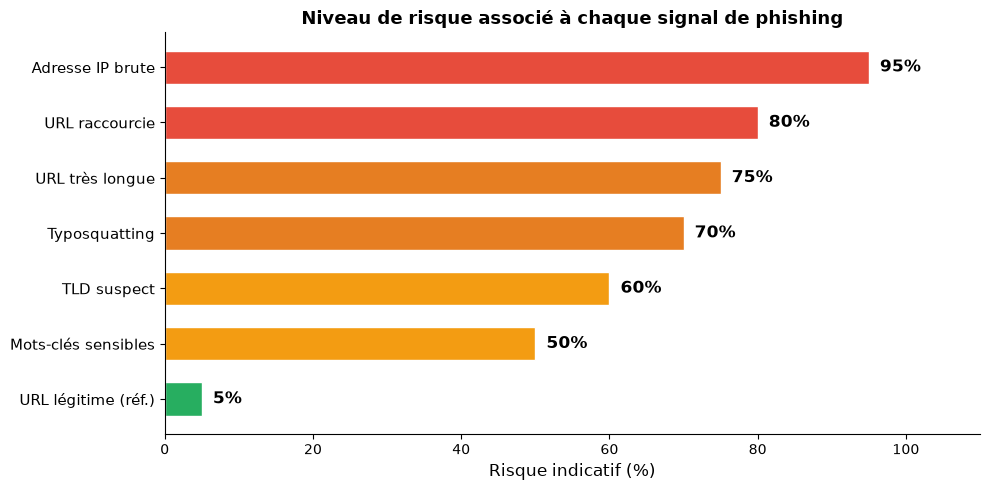

In [22]:
import seaborn as sns

signaux = [
    "URL légitime (réf.)", "Mots-clés sensibles", "TLD suspect",
    "Typosquatting", "URL très longue", "URL raccourcie", "Adresse IP brute"
]
risques = [5, 50, 60, 70, 75, 80, 95]
couleurs = ['#27ae60', '#f39c12', '#f39c12',
            '#e67e22', '#e67e22', '#e74c3c', '#e74c3c']

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(signaux, risques, color=couleurs, height=0.6, edgecolor='white')

for bar, val in zip(bars, risques):
    ax.text(bar.get_width() + 1.5, bar.get_y() + bar.get_height()/2,
            f'{val}%', va='center', fontweight='bold', fontsize=12)

ax.set_xlim(0, 110)
ax.set_xlabel("Risque indicatif (%)", fontsize=12)
ax.set_title("Niveau de risque associé à chaque signal de phishing",
             fontweight='bold', fontsize=13)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='y', labelsize=11)

plt.tight_layout()
plt.savefig("signaux_risque.png", dpi=200, bbox_inches='tight')
plt.show()

---

## Références bibliographiques

1. **APWG (2025)**. *Phishing Activity Trends Report*. Anti-Phishing Working Group. Disponible sur : [https://apwg.org/reporting/trends-reports/](https://apwg.org/reporting/trends-reports/)
2. **Verizon (2024)**. *Data Breach Investigations Report (DBIR)*. Verizon Business. Disponible sur : [https://www.verizon.com/business/resources/reports/dbir/](https://www.verizon.com/business/resources/reports/dbir/)
3. **IBM Security (2024)**. *Cost of a Data Breach Report*. IBM. Disponible sur : [https://www.ibm.com/reports/data-breach](https://www.ibm.com/reports/data-breach)
4. **ANSSI (2024)**. *Panorama de la cybermenace*. ANSSI. Disponible sur : [https://www.ssi.gouv.fr/](https://www.ssi.gouv.fr/)